# Regularization

We are going to look at a dataset on baseball to see if we can predict a player's salary.


## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler


## Read in Data

In [2]:
url = "http://ddc-datascience.s3.amazonaws.com/Hitters.csv"
hits = pd.read_csv( url )
hits.head()

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


In [3]:
hits.shape

(322, 20)

In [4]:
hits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 20 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   AtBat      322 non-null    int64  
 1   Hits       322 non-null    int64  
 2   HmRun      322 non-null    int64  
 3   Runs       322 non-null    int64  
 4   RBI        322 non-null    int64  
 5   Walks      322 non-null    int64  
 6   Years      322 non-null    int64  
 7   CAtBat     322 non-null    int64  
 8   CHits      322 non-null    int64  
 9   CHmRun     322 non-null    int64  
 10  CRuns      322 non-null    int64  
 11  CRBI       322 non-null    int64  
 12  CWalks     322 non-null    int64  
 13  League     322 non-null    object 
 14  Division   322 non-null    object 
 15  PutOuts    322 non-null    int64  
 16  Assists    322 non-null    int64  
 17  Errors     322 non-null    int64  
 18  Salary     263 non-null    float64
 19  NewLeague  322 non-null    object 
dtypes: float64

In [5]:
hits.describe(include = "all").transpose()

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
AtBat,322.0,NaN,NaN,NaN,380.928571,153.404981,16.0,255.25,379.5,512.0,687.0
Hits,322.0,NaN,NaN,NaN,101.024845,46.454741,1.0,64.0,96.0,137.0,238.0
HmRun,322.0,NaN,NaN,NaN,10.770186,8.709037,0.0,4.0,8.0,16.0,40.0
Runs,322.0,NaN,NaN,NaN,50.909938,26.024095,0.0,30.25,48.0,69.0,130.0
RBI,322.0,NaN,NaN,NaN,48.02795,26.166895,0.0,28.0,44.0,64.75,121.0
Walks,322.0,NaN,NaN,NaN,38.742236,21.639327,0.0,22.0,35.0,53.0,105.0
Years,322.0,NaN,NaN,NaN,7.444099,4.926087,1.0,4.0,6.0,11.0,24.0
CAtBat,322.0,NaN,NaN,NaN,2648.68323,2324.20587,19.0,816.75,1928.0,3924.25,14053.0
CHits,322.0,NaN,NaN,NaN,717.571429,654.472627,4.0,209.0,508.0,1059.25,4256.0
CHmRun,322.0,NaN,NaN,NaN,69.490683,86.266061,0.0,14.0,37.5,90.0,548.0


## Data Cleaning

### Backup

In [6]:
# Backup
hits_clean = hits.copy()
hits_clean


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317,497,127,7,65,48,37,5,2703,806,32,379,311,138,N,E,325,9,3,700.0,N
318,492,136,5,76,50,94,12,5511,1511,39,897,451,875,A,E,313,381,20,875.0,A
319,475,126,3,61,43,52,6,1700,433,7,217,93,146,A,W,37,113,7,385.0,A
320,573,144,9,85,60,78,8,3198,857,97,470,420,332,A,E,1314,131,12,960.0,A


In [7]:
# Restore
hits = hits_clean.copy()
hits


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317,497,127,7,65,48,37,5,2703,806,32,379,311,138,N,E,325,9,3,700.0,N
318,492,136,5,76,50,94,12,5511,1511,39,897,451,875,A,E,313,381,20,875.0,A
319,475,126,3,61,43,52,6,1700,433,7,217,93,146,A,W,37,113,7,385.0,A
320,573,144,9,85,60,78,8,3198,857,97,470,420,332,A,E,1314,131,12,960.0,A


### Check for nulls


In [8]:
# Check for NAs
hits_clean.isnull().sum()*1000


,0
AtBat,0
Hits,0
HmRun,0
Runs,0
RBI,0
Walks,0
Years,0
CAtBat,0
CHits,0
CHmRun,0


In [9]:
nulls = hits_clean.isnull().sum()
nulls


,0
AtBat,0
Hits,0
HmRun,0
Runs,0
RBI,0
Walks,0
Years,0
CAtBat,0
CHits,0
CHmRun,0


In [10]:
filter = nulls > 0
filter

,0
AtBat,False
Hits,False
HmRun,False
Runs,False
RBI,False
Walks,False
Years,False
CAtBat,False
CHits,False
CHmRun,False


In [11]:
nulls[ filter ]/(hits_clean.shape[0])*100

,0
Salary,18.322981


All the NAs are in the Salary column. Since the salary column is our response, we need to remove rows that contain NAs.

In [12]:
# Remove rows with NAs
hits_clean.dropna(
  subset = ["Salary"],
  axis = 0,
  inplace = True,
)

In [ ]:
# pd.DataFrame.dropna?

In [13]:
# Confirm they were removed
hits_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 263 entries, 1 to 321
Data columns (total 20 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   AtBat      263 non-null    int64  
 1   Hits       263 non-null    int64  
 2   HmRun      263 non-null    int64  
 3   Runs       263 non-null    int64  
 4   RBI        263 non-null    int64  
 5   Walks      263 non-null    int64  
 6   Years      263 non-null    int64  
 7   CAtBat     263 non-null    int64  
 8   CHits      263 non-null    int64  
 9   CHmRun     263 non-null    int64  
 10  CRuns      263 non-null    int64  
 11  CRBI       263 non-null    int64  
 12  CWalks     263 non-null    int64  
 13  League     263 non-null    object 
 14  Division   263 non-null    object 
 15  PutOuts    263 non-null    int64  
 16  Assists    263 non-null    int64  
 17  Errors     263 non-null    int64  
 18  Salary     263 non-null    float64
 19  NewLeague  263 non-null    object 
dtypes: float64(1), 

In [14]:
hits_clean.isnull().sum()*1000

,0
AtBat,0
Hits,0
HmRun,0
Runs,0
RBI,0
Walks,0
Years,0
CAtBat,0
CHits,0
CHmRun,0


In [15]:
nulls = hits_clean.isnull().sum()
filter = nulls > 0
nulls[ filter ]/(hits_clean.index.size)*100

,0


NAs were successfully removed. Now we notice that some of the columns are object type. Let's take a look at those.

In [16]:
hits_clean.dtypes.value_counts()

,count
int64,16
object,3
float64,1


In [17]:
hits_clean.dtypes.sort_values()

,0
AtBat,int64
Errors,int64
Assists,int64
PutOuts,int64
CWalks,int64
CRBI,int64
CRuns,int64
CHits,int64
CHmRun,int64
Years,int64


### Backup

In [18]:
# make a backup
hits_clean_bak = hits_clean.copy()
hits_clean_bak

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N
5,594,169,4,74,51,35,11,4408,1133,19,501,336,194,A,W,282,421,25,750.0,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317,497,127,7,65,48,37,5,2703,806,32,379,311,138,N,E,325,9,3,700.0,N
318,492,136,5,76,50,94,12,5511,1511,39,897,451,875,A,E,313,381,20,875.0,A
319,475,126,3,61,43,52,6,1700,433,7,217,93,146,A,W,37,113,7,385.0,A
320,573,144,9,85,60,78,8,3198,857,97,470,420,332,A,E,1314,131,12,960.0,A


In [19]:
# restore from backup
hits_clean = hits_clean_bak.copy()
hits_clean

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N
5,594,169,4,74,51,35,11,4408,1133,19,501,336,194,A,W,282,421,25,750.0,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317,497,127,7,65,48,37,5,2703,806,32,379,311,138,N,E,325,9,3,700.0,N
318,492,136,5,76,50,94,12,5511,1511,39,897,451,875,A,E,313,381,20,875.0,A
319,475,126,3,61,43,52,6,1700,433,7,217,93,146,A,W,37,113,7,385.0,A
320,573,144,9,85,60,78,8,3198,857,97,470,420,332,A,E,1314,131,12,960.0,A


### League

In [20]:
# League column
hits_clean['League'].value_counts()

,count
League,
A,139
N,124


In [22]:
# Since it only has two values, we can label encode
hits_clean['League'] = hits_clean['League'].replace({'A': "1", 'N': "0"}).astype(int)


In [23]:
hits_clean['League'].value_counts()

,count
League,
1,139
0,124


### Division

In [24]:
# Division column
hits_clean['Division'].value_counts()

,count
Division,
W,134
E,129


In [25]:
# Since it only has two values, we can label encode
hits_clean['Division'] = hits_clean['Division'].replace({'W': "1", 'E': "0"}).astype(int)

In [26]:
hits_clean['Division'].value_counts()

,count
Division,
1,134
0,129


### New League

In [27]:
# New League column
hits_clean['NewLeague'].value_counts()

,count
NewLeague,
A,141
N,122


In [28]:
# Since it only has two values, we can label encode
hits_clean['NewLeague'] = hits_clean['NewLeague'].replace({'A': "1", 'N': "0"}).astype(int)

In [29]:
hits_clean['NewLeague'].value_counts()

,count
NewLeague,
1,141
0,122


In [30]:
hits_clean.head()

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,0,1,632,43,10,475.0,0
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,1,1,880,82,14,480.0,1
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,0,0,200,11,3,500.0,0
4,321,87,10,39,42,30,2,396,101,12,48,46,33,0,0,805,40,4,91.5,0
5,594,169,4,74,51,35,11,4408,1133,19,501,336,194,1,1,282,421,25,750.0,1


In [31]:
hits_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 263 entries, 1 to 321
Data columns (total 20 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   AtBat      263 non-null    int64  
 1   Hits       263 non-null    int64  
 2   HmRun      263 non-null    int64  
 3   Runs       263 non-null    int64  
 4   RBI        263 non-null    int64  
 5   Walks      263 non-null    int64  
 6   Years      263 non-null    int64  
 7   CAtBat     263 non-null    int64  
 8   CHits      263 non-null    int64  
 9   CHmRun     263 non-null    int64  
 10  CRuns      263 non-null    int64  
 11  CRBI       263 non-null    int64  
 12  CWalks     263 non-null    int64  
 13  League     263 non-null    int64  
 14  Division   263 non-null    int64  
 15  PutOuts    263 non-null    int64  
 16  Assists    263 non-null    int64  
 17  Errors     263 non-null    int64  
 18  Salary     263 non-null    float64
 19  NewLeague  263 non-null    int64  
dtypes: float64(1), 

In [32]:
hits_clean.dtypes.sort_values()

,0
AtBat,int64
Errors,int64
Assists,int64
PutOuts,int64
Division,int64
League,int64
CWalks,int64
CRBI,int64
CRuns,int64
CHmRun,int64


## EDA

### Correlation matrix plot


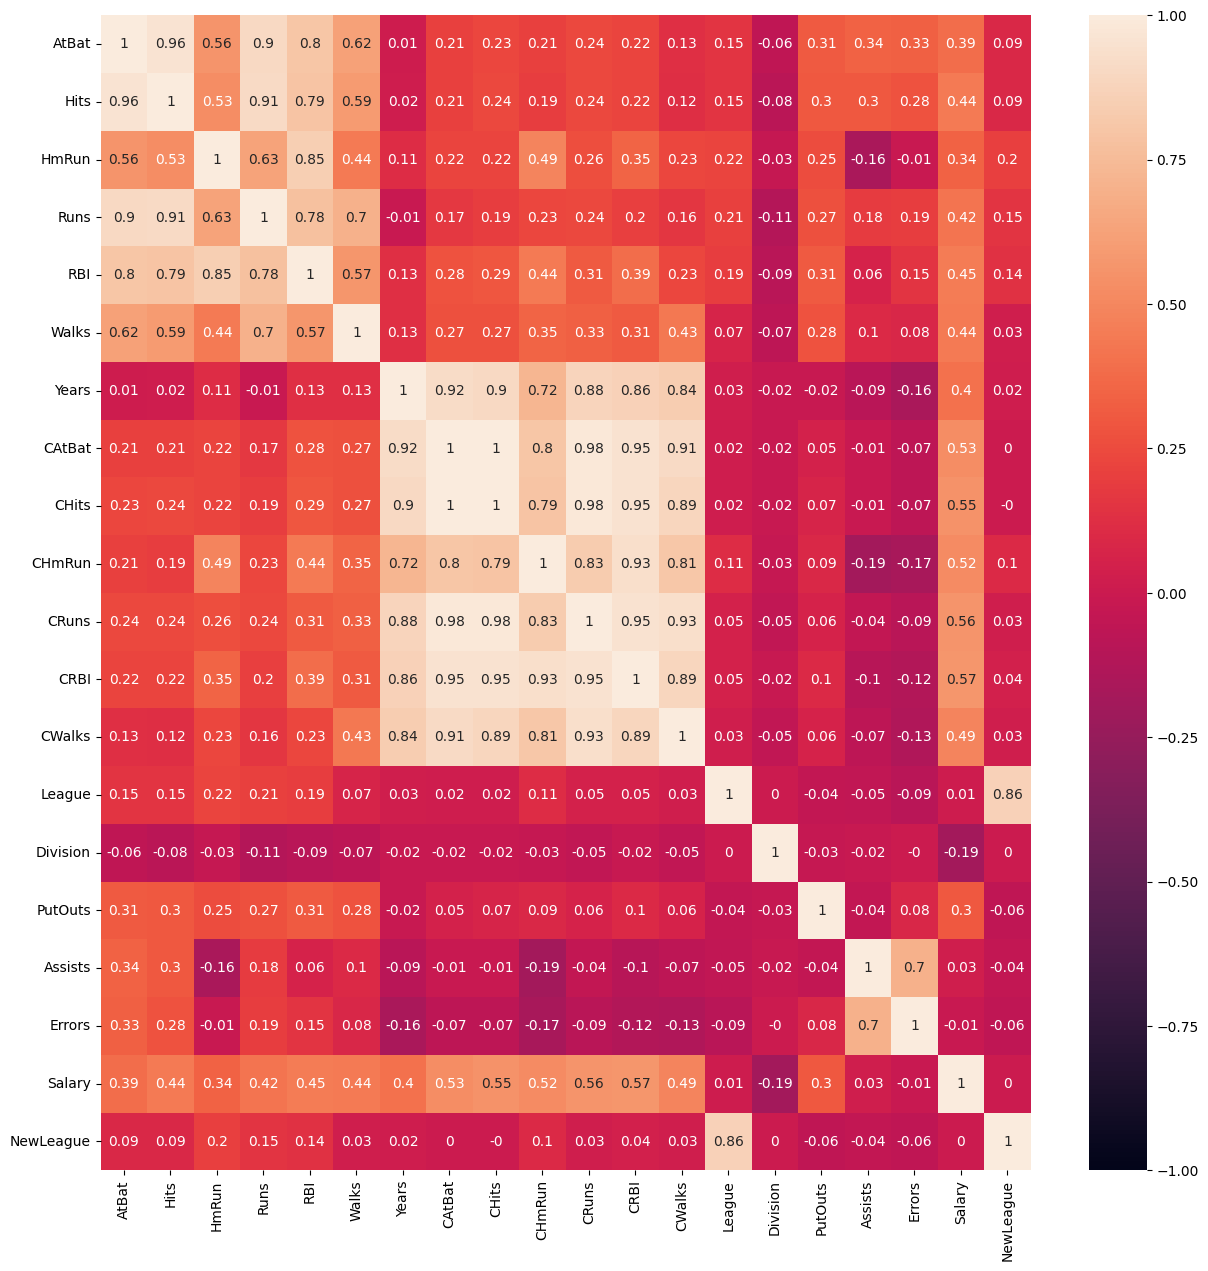

In [33]:
# Let's take a look at a correlation plot
plt.figure(figsize=(15,15))
correlation_matrix = hits_clean.corr().round(2)
sns.heatmap(
    data=correlation_matrix,
    annot=True,
    vmin=-1,
    vmax=1,
) ;

### Correlation matrix plot - lower triangle


In [34]:
np.set_printoptions(linewidth=200, suppress=True)

ones = np.ones_like(
    correlation_matrix,
    dtype=bool,
)
ones


array([[ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True, 

In [35]:
# Create a mask
mask = np.tril(ones, k=-1)
mask


array([[False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False],
       [ True, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False],
       [ True,  True, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False],
       [ True,  True,  True, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False],
       [ True,  True,  True,  True, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False],
       [ True,  True,  True,  True,  True, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False],
       [ True,  True,  True,  True,  True,  True, False, False, False, False, False, False, False, False, 

In [36]:
lower_triangle_corr = correlation_matrix.where(mask)
lower_triangle_corr


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
AtBat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hits,0.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HmRun,0.56,0.53,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Runs,0.90,0.91,0.63,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RBI,0.80,0.79,0.85,0.78,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Walks,0.62,0.59,0.44,0.70,0.57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Years,0.01,0.02,0.11,-0.01,0.13,0.13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CAtBat,0.21,0.21,0.22,0.17,0.28,0.27,0.92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CHits,0.23,0.24,0.22,0.19,0.29,0.27,0.90,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CHmRun,0.21,0.19,0.49,0.23,0.44,0.35,0.72,0.80,0.79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


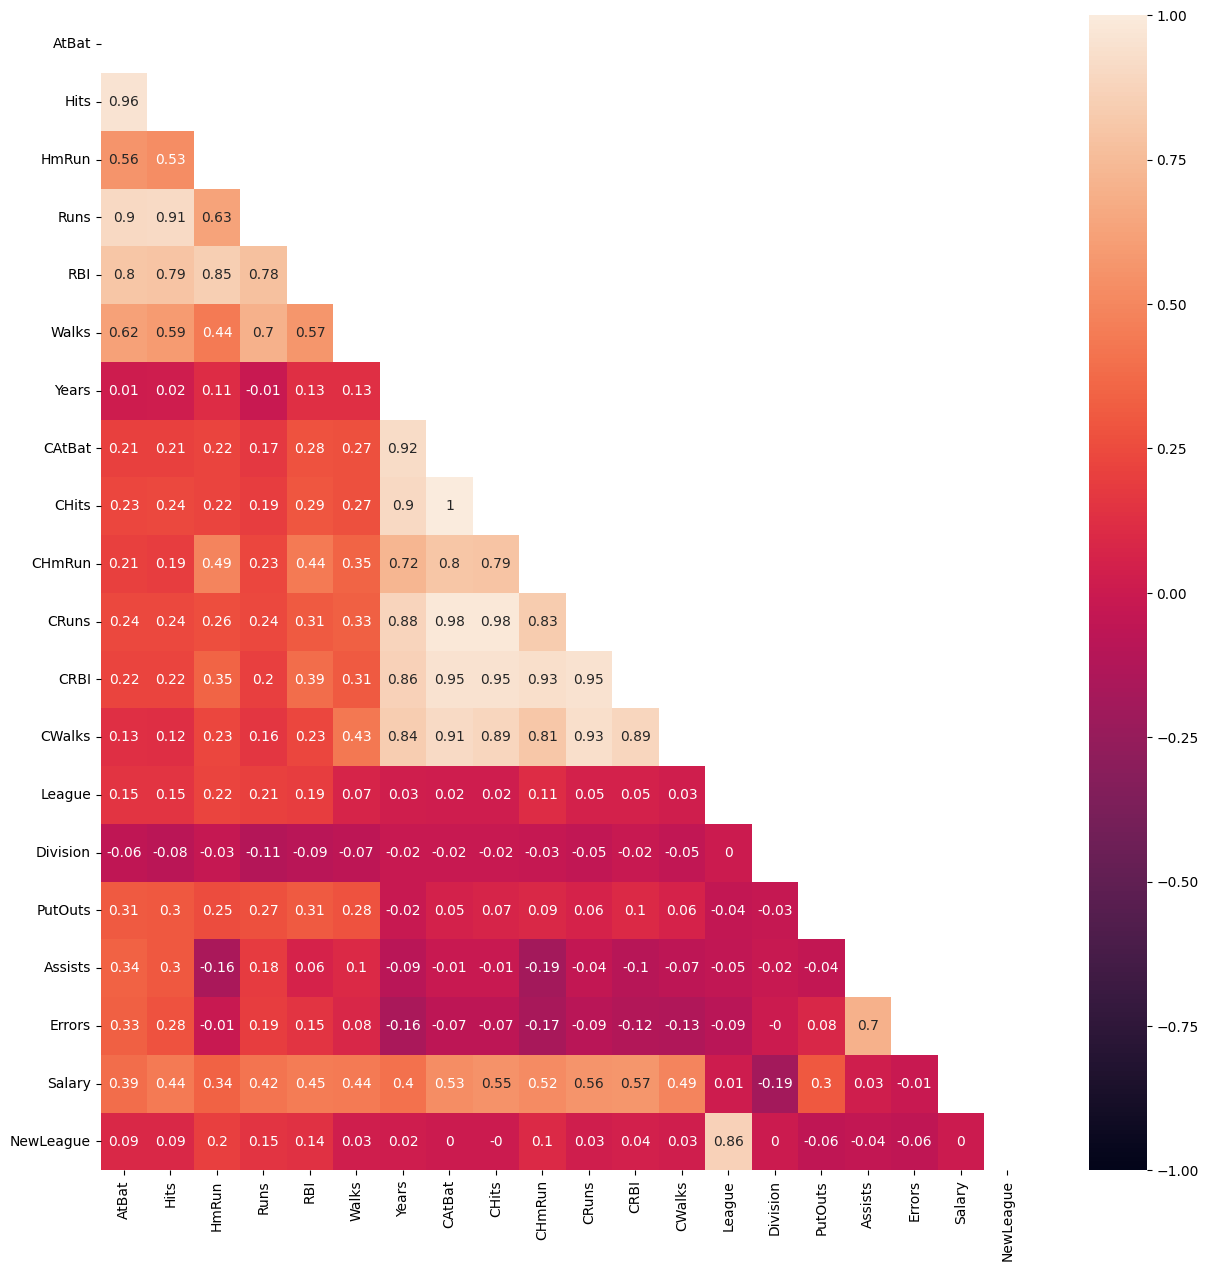

In [37]:
plt.figure(figsize=(15,15))
sns.heatmap(
    data=lower_triangle_corr,
    annot=True,
    vmin=-1,
    vmax=1,
) ;

Create a list of the most highly correlated.

In [46]:
lt_df = (
  lower_triangle_corr
  .abs()
  .unstack()
  .to_frame()
  .rename( columns={0:"A"} )
  .query( "A > 0.90")
  .sort_values( by = "A", ascending=False )
  .reset_index()
)
lt_df


,level_0,level_1,A
0,CAtBat,CHits,1.00
1,CAtBat,CRuns,0.98
2,CHits,CRuns,0.98
3,AtBat,Hits,0.96
4,CRuns,CRBI,0.95
5,CHits,CRBI,0.95
6,CAtBat,CRBI,0.95
7,CHmRun,CRBI,0.93
8,CRuns,CWalks,0.93
9,Years,CAtBat,0.92


In [47]:
# get list of highly correlated features
list(enumerate(set(lt_df.iloc[:,:2].stack().sort_values().to_list())))


[(0, 'CAtBat'),
 (1, 'CHmRun'),
 (2, 'CRBI'),
 (3, 'CWalks'),
 (4, 'Runs'),
 (5, 'CRuns'),
 (6, 'CHits'),
 (7, 'Hits'),
 (8, 'Years'),
 (9, 'AtBat')]

Several of the predictors are highly correlated and cluster into two groups:
- Years, CAtBat, CHits, CHmRun, CRuns, CRBI, CWalks
- AtBat, Hits, Runs

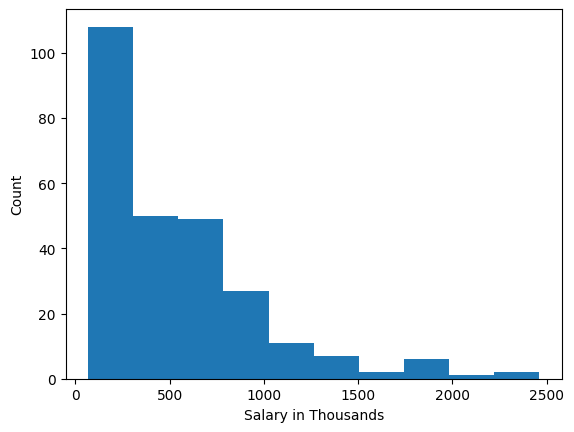

In [48]:
# Let's look at the distribution of salaries
plt.hist(hits_clean['Salary'])
plt.xlabel('Salary in Thousands')
plt.ylabel("Count")
plt.savefig('test.png')

Within each group, the features that are most highly correlated with salary are CRBI and Hits.

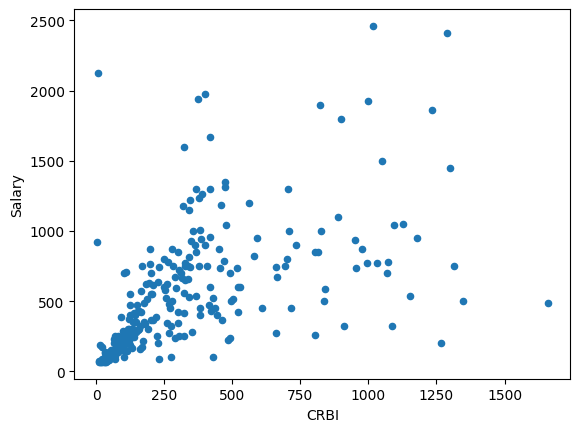

In [49]:
# Let's look at a scatterplot of CRBI and Salary
hits_clean.plot('CRBI', 'Salary', kind = 'scatter') ;

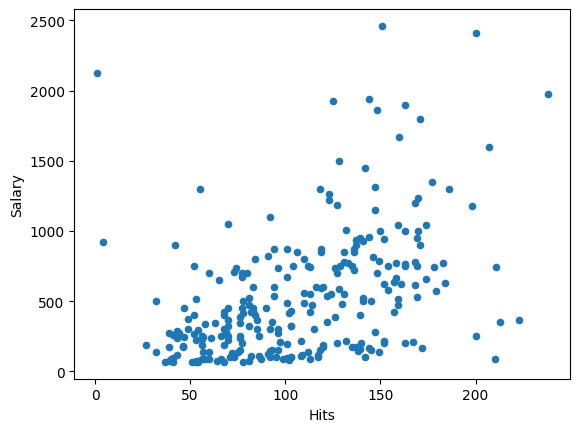

In [50]:
# Let's look at a scatterplot of hits and salary
hits_clean.plot('Hits', 'Salary', kind = 'scatter') ;

## Linear Regression
We will first fit a multiple linear regression model. We are going to drop some of the highly correlated predictors and keep the two most highly correlated with Salary: Hits and CRBI.

In [73]:
# First we will break up our data into training and testing sets

# trimmed_df = hits_clean[['Salary', 'AtBat', 'Hits', 'Years']].copy()
# trimmed_df = hits_clean[['Salary', 'Hits', 'Years']].copy()
trimmed_df = hits_clean[['Salary', 'AtBat', 'Years']].copy()
trimmed_df


,Salary,AtBat,Years
1,475.0,315,14
2,480.0,479,3
3,500.0,496,11
4,91.5,321,2
5,750.0,594,11
...,...,...,...
317,700.0,497,5
318,875.0,492,12
319,385.0,475,6
320,960.0,573,8


In [98]:
X = hits_clean.drop(['CRuns', 'CHmRun', 'CHits', 'CAtBat', 'CWalks', 'Runs', 'AtBat', 'Years', 'Salary'], axis = 1).copy()



In [99]:
X = trimmed_df.drop(columns = ['Salary'])
y = trimmed_df['Salary']

# normalize the features
scaler = StandardScaler()
scaler.fit_transform(X)


array([[-0.6029005 ,  1.3978935 ],
       [ 0.51254171, -0.90120024],
       [ 0.62816682,  0.77086793],
       [-0.56209164, -1.11020876],
       [ 1.29471156,  0.77086793],
       [-1.4870925 , -1.11020876],
       [-0.71852561, -0.90120024],
       [-0.54848868, -1.11020876],
       [-0.01797348,  1.18888498],
       [ 1.15868202,  0.56185941],
       [-1.37146739,  0.35285089],
       [ 0.09765162, -0.69219172],
       [-1.11981274, -0.27417468],
       [-1.41227625,  1.18888498],
       [ 1.11787316,  1.60690202],
       [-1.45308511, -0.4831832 ],
       [-1.88157816,  0.14384237],
       [ 0.06364424, -1.31921729],
       [ 0.15206344, -1.31921729],
       [ 0.46493138, -0.27417468],
       [ 1.53276325,  2.23392759],
       [ 1.24710122, -0.27417468],
       [-0.54168721, -0.06516616],
       [ 0.47853433,  0.56185941],
       [ 0.99544658, -0.4831832 ],
       [ 0.74379193,  1.3978935 ],
       [ 0.1044531 , -0.90120024],
       [ 1.21989531, -0.4831832 ],
       [-1.35786444,

In [100]:
X.columns


Index(['AtBat', 'Years'], dtype='object')

In [101]:
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size = 0.2, random_state=5)


In [102]:
X.head()


,AtBat,Years
1,315,14
2,479,3
3,496,11
4,321,2
5,594,11


In [103]:
X_scaled.head()


,AtBat,Years
0,-0.602900,1.397893
1,0.512542,-0.901200
2,0.628167,0.770868
3,-0.562092,-1.110209
4,1.294712,0.770868


In [104]:
X_scaled.describe().transpose()


,count,mean,std,min,25%,50%,75%,max
AtBat,263.0,1.013131e-17,1.001907,-2.616138,-0.823948,0.063644,0.832211,1.927249
Years,263.0,-5.403367e-17,1.001907,-1.319217,-0.692192,-0.274175,0.561859,3.487979


In [105]:
# Fit a linear model using Sklearn
model = LinearRegression()
my_fit_lr = model.fit(X_train, y_train)


In [106]:
# Create a data frame with the results from the linear regression models
model_results = pd.DataFrame()
model_results['Predictor'] = X_train.columns
model_results['Linear'] = my_fit_lr.coef_
model_results.sort_values(by=['Linear'],inplace=True, ascending=False)
model_results


,Predictor,Linear
0,AtBat,204.126985
1,Years,190.910357


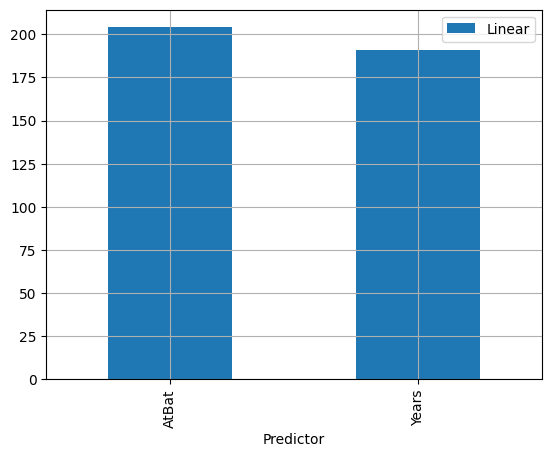

In [107]:
# We can even plot the coefficients if we want to!
model_results.plot(x = 'Predictor', y = 'Linear', kind = 'bar')
plt.grid()


In [108]:
# Calculate CV RMSE
results = cross_val_score(
    model,
    X_scaled,
    y,
    scoring='neg_root_mean_squared_error',
    cv = 10
    )
rmse = abs(results.mean())
print(f"CV RMSE: {rmse}")


CV RMSE: 366.1313104847557


- both: CV RMSE: 359.4996029118099
- with Hits: CV RMSE: 358.6910385178394
- with AtBats: CV RMSE: 366.1313104847557


This is showing that we have a RMSE of about $360k.

**NOTE**: We did not do any residual analysis in this example, although it is an important part of checking the assumptions of a linear regression model. Please refer back to the linear regression lecture for an example of how to check residuals.

## Regularization - Ridge Regression

Ridge regression is ideal for preventing overfitting and stabilizing model coefficients when your dataset suffers from multicollinearity. Instead of dropping correlated features, it shrinks their weights proportionally and keeps them all in the model. Use it when you want reliable out-of-sample predictions without having to manually prune redundant variables.

However, in this example, we'll use the trimmed data frame from the Linear Regression for comparison.


In [84]:
# Train the model
my_fit_rr = Ridge(alpha = 1) # Arbitrarily choosing alpha = 1
my_fit_rr.fit(X_train, y_train) ;

In [85]:
# Calculate RMSE
y_pred = my_fit_rr.predict(X_test)
rmse = np.sqrt(np.mean(np.square(y_test - y_pred)))
print(f"RMSE: {rmse}")

RMSE: 443.8506844224651


Let's try looking at different values of $\alpha$.

In [86]:
# Specify values of alpha we want to try
alpha = [1e-15, 1e-10, 1e-8, 1e-4, 1e-3, 1e-2, 1e-1, 1, 2, 3, 4, 5, 10, 20, 30, 50]

# Create empty list to hold results
results_alpha = []

for a in alpha:
  # Train the model
  my_fit_rr = Ridge(alpha = a) # Looping through alpha
  my_fit_rr.fit(X_train, y_train)

  # Calculate CV RMSE
  results = cross_val_score(
      my_fit_rr,
      X_scaled,
      y,
      scoring='neg_root_mean_squared_error',
      cv = 10
      )
  rmse = abs(results.mean())
  results_alpha.append(rmse)

results_df = pd.DataFrame({'Alpha': alpha, 'RMSE': results_alpha})
print(results_df.sort_values(by=['RMSE']))

           Alpha        RMSE
13  2.000000e+01  365.801653
12  1.000000e+01  365.811444
11  5.000000e+00  365.927938
10  4.000000e+00  365.961336
9   3.000000e+00  365.998287
14  3.000000e+01  366.036527
8   2.000000e+00  366.038875
7   1.000000e+00  366.083187
6   1.000000e-01  366.126324
5   1.000000e-02  366.130810
4   1.000000e-03  366.131260
3   1.000000e-04  366.131305
2   1.000000e-08  366.131310
1   1.000000e-10  366.131310
0   1.000000e-15  366.131310
15  5.000000e+01  367.040852


In [87]:
results_df.sort_values( by = ["Alpha"])

,Alpha,RMSE
0,1.000000e-15,366.131310
1,1.000000e-10,366.131310
2,1.000000e-08,366.131310
3,1.000000e-04,366.131305
4,1.000000e-03,366.131260
5,1.000000e-02,366.130810
6,1.000000e-01,366.126324
7,1.000000e+00,366.083187
8,2.000000e+00,366.038875
9,3.000000e+00,365.998287


<Axes: >

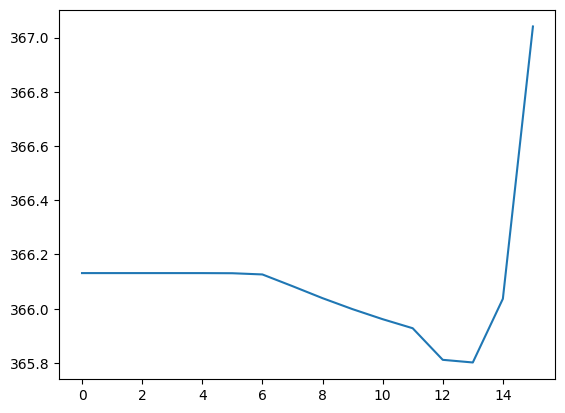

In [88]:
results_df.sort_values( by = ["Alpha"])["RMSE"].plot()

# FIXME : plot by alpha not index


It looks like 20 gives us the smallest RMSE.

In [89]:
# Retrain the model w/ alpha = 20
my_fit_rr = Ridge(alpha = 30)
my_fit_rr.fit(X_train, y_train)

# Calculate CV RMSE
results = cross_val_score(my_fit_rr, X_scaled, y, scoring='neg_root_mean_squared_error', cv = 10)
rmse = abs(results.mean())
print(f"CV RMSE: {rmse}")

CV RMSE: 366.0365272510447


In [90]:
# Add ridge regression results to data frame we created earlier
model_results['Ridge'] = my_fit_rr.coef_

In [91]:
model_results

,Predictor,Linear,Ridge
0,AtBat,204.126985,179.521741
1,Years,190.910357,166.484258


## Regularization - Lasso Regression


Lasso regression is ideal when you want automated feature selection, as its L1 penalty can shrink coefficient values all the way down to zero. This makes it exceptionally useful for high-dimensional datasets where you need to filter out noise and identify the most critical predictors. Ultimately, it produces simpler, highly sparse models that are much easier to interpret and less prone to overfitting.


In [92]:
# Specify values of alpha we want to try
alpha = [1e-15, 1e-10, 1e-8, 1e-4, 1e-3, 1e-2, 1e-1, 1, 2, 3, 4, 5, 10, 20, 30, 50]

# Create empty list to hold results
results_alpha = []

for a in alpha:
  # Train the model
  my_fit_lasso = Lasso(alpha = a, tol = .01, max_iter=100_000) # Looping through alpha
  my_fit_lasso.fit(X_train, y_train)

  # Calculate CV RMSE
  results = cross_val_score(
      my_fit_lasso,
      X_scaled,
      y,
      scoring='neg_root_mean_squared_error',
      cv = 10
  )
  rmse = abs(results.mean())
  results_alpha.append(rmse)

results_df = pd.DataFrame({'Alpha': alpha, 'RMSE': results_alpha})
print(results_df.sort_values(by=['RMSE']))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.736e+07, tolerance: 5.077e+05
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.589e+07, tolerance: 4.839e+05
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.568e+07, tolerance: 4.976e

           Alpha        RMSE
11  5.000000e+00  366.057369
10  4.000000e+00  366.060122
9   3.000000e+00  366.068897
8   2.000000e+00  366.083689
7   1.000000e+00  366.104494
6   1.000000e-01  366.128357
5   1.000000e-02  366.131011
4   1.000000e-03  366.131279
3   1.000000e-04  366.131306
2   1.000000e-08  366.131310
1   1.000000e-10  366.131310
0   1.000000e-15  366.131310
12  1.000000e+01  366.133990
13  2.000000e+01  366.739249
14  3.000000e+01  367.944635
15  5.000000e+01  372.121872


In [93]:
results_df

,Alpha,RMSE
0,1.000000e-15,366.131310
1,1.000000e-10,366.131310
2,1.000000e-08,366.131310
3,1.000000e-04,366.131306
4,1.000000e-03,366.131279
5,1.000000e-02,366.131011
6,1.000000e-01,366.128357
7,1.000000e+00,366.104494
8,2.000000e+00,366.083689
9,3.000000e+00,366.068897


In [94]:
# Train the model
my_fit_lasso = Lasso(alpha = 5, tol = .01, max_iter=1_000_000)
my_fit_lasso.fit(X_train, y_train)

# Calculate CV RMSE
results = cross_val_score(my_fit_lasso, X_scaled, y, scoring='neg_root_mean_squared_error', cv = 10)
rmse = abs(results.mean())
print(f"CV RMSE: {rmse}")

CV RMSE: 366.057368516726


In [95]:
# Add Lasso results to the data frame we created before
model_results['Lasso'] = my_fit_lasso.coef_

## Summary

In [96]:
model_results

,Predictor,Linear,Ridge,Lasso
0,AtBat,204.126985,179.521741,199.347791
1,Years,190.910357,166.484258,185.755992


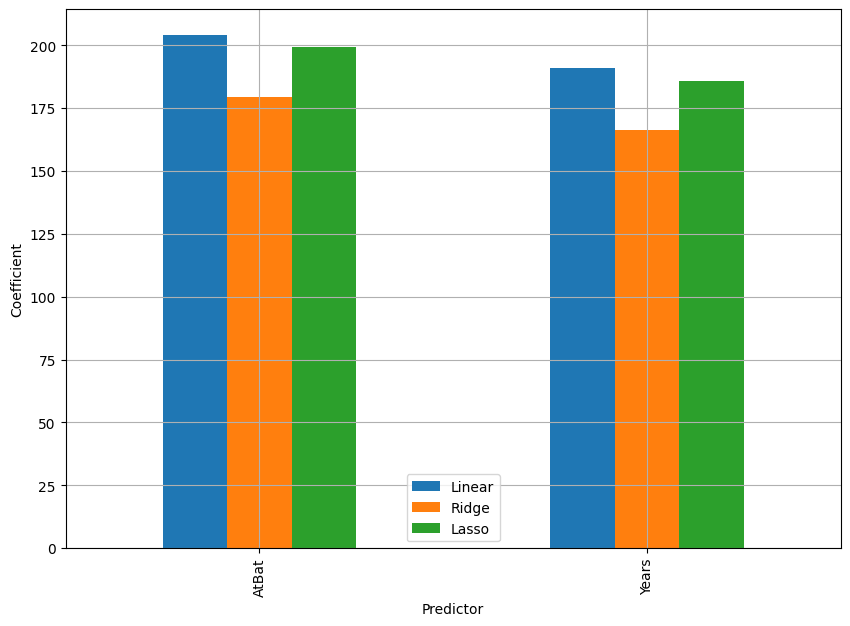

In [97]:
# Plot results
fig, ax = plt.subplots(1,1, figsize = (10,7))
model_results.plot(x = 'Predictor', kind = 'bar', ax = ax)
ax.set_ylabel('Coefficient')
plt.grid()

After performing regularization, we were able to reduce our RMSE from
\$360k with linear regression to
\$329k with Ridge regression to
\$327k with Lasso regression.

For all models, CRBI seems to be one of the more important predictors of salary.

